In [1]:
import sys
import json

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

sys.path.append("../../PG_PyTraining")
from common.pg.pg_geometry import PgCamera

In [45]:
DESK_H = 730 # cm
CAMERA_H = 2560 # cm

W, H = 1280, 720

COEFS = np.array([640 / W, 480 / H])
COEFS

array([0.5       , 0.66666667])

In [46]:
def rectangle_to_polygon(rectangle, n):
    # Extract coordinates of top-left and bottom-right corners
    top_left = rectangle[0]
    bottom_right = rectangle[1]

    # Calculate coordinates of other corners
    top_right = np.array([top_left[0], bottom_right[1]])
    bottom_left = np.array([bottom_right[0], top_left[1]])

    # Generate points along each side
    top_side = np.linspace(top_left, top_right, n, endpoint=False)
    right_side = np.linspace(top_right, bottom_right, n, endpoint=False)
    bottom_side = np.linspace(bottom_right, bottom_left, n, endpoint=False)
    left_side = np.linspace(bottom_left, top_left, n, endpoint=False)

    # Combine points to form the polygon
    polygon = np.concatenate([top_side, right_side, bottom_side, left_side])

    return polygon

In [47]:
base_camera = PgCamera(CAMERA_H, "Cam2")
desk_camera = PgCamera(CAMERA_H - DESK_H, "Cam2")

In [89]:
with open("data/Cam2_H256_atiryeda_mr_0101_2.json", "rt") as f:
    data = json.load(f)
data = data["shapes"]

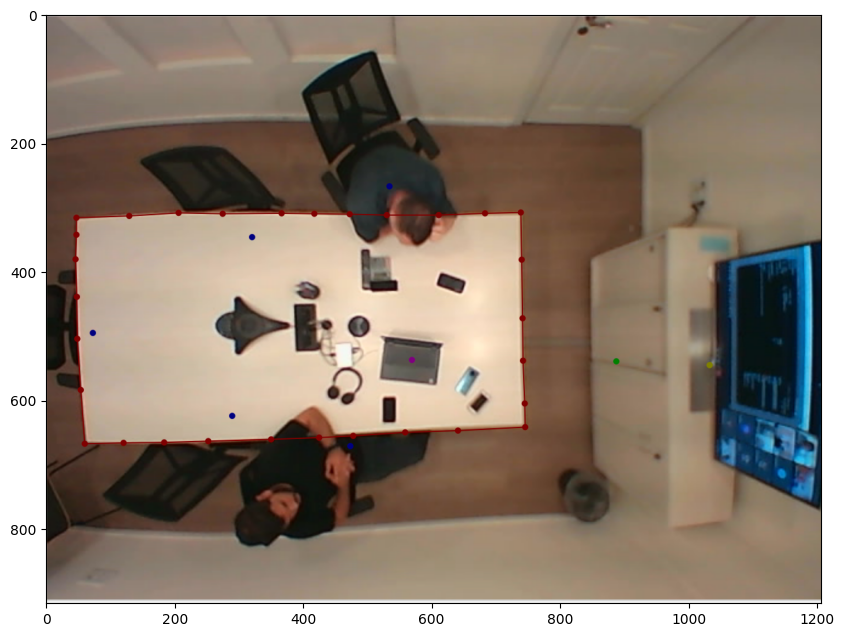

In [112]:
img = cv2.cvtColor(cv2.imread("data/example.png"), cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(img)

<Figure size 2000x1000 with 0 Axes>

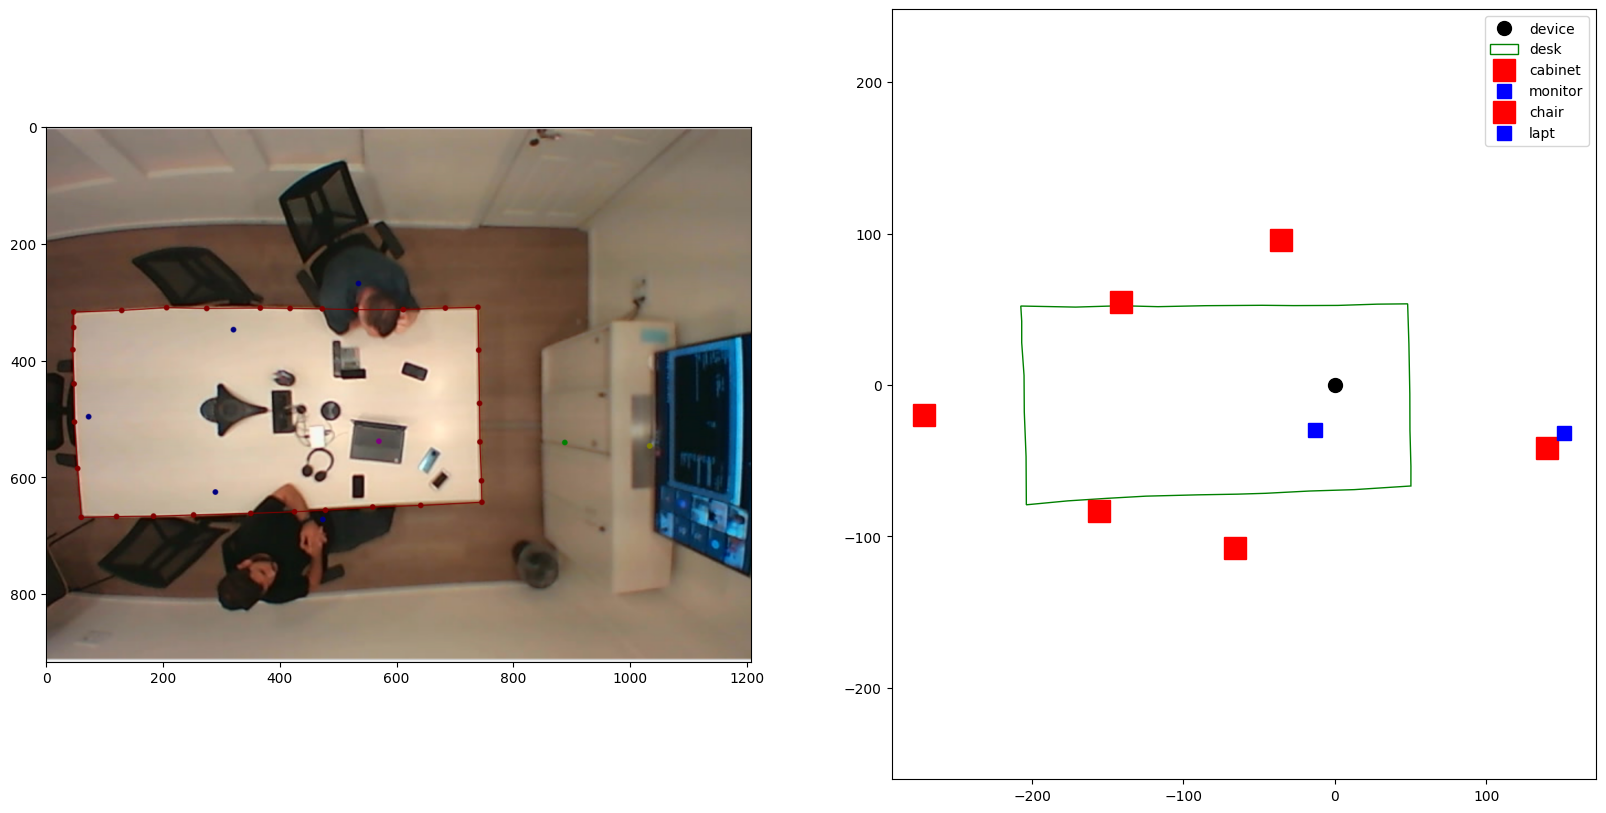

In [132]:
plt.figure(figsize=(20, 10))
fig, ax = plt.subplots(1, 2, figsize=(20, 10)) 

ax[0].imshow(img)

device_pos = base_camera.pixel2cm([[320, 240]])[0]

plt.plot(*device_pos, 'ko', markersize=10,  label="device")

for shape in data:
    if shape["label"] == "desk_mask":
        points = desk_camera.pixel2cm(shape["points"])
        ax[1].add_patch(Polygon(points, fill=False, color="g", label="desk"))
    elif shape["label"] in ["monitor_pos", "laptop_pos"]:
        points = desk_camera.pixel2cm(shape["points"])[0]
        plt.plot(*points, 'bs', markersize=10,  label=shape["label"].strip("_pos"))
    elif shape["label"] in ["chair_pos", "cabinet_pos"]:
        points = base_camera.pixel2cm(shape["points"])[0]

        plt.plot(*points, 'rs', markersize=16,  label=shape["label"].strip("_pos"))

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

ax[1].axis("equal")
# plt.legend()
plt.show()